# Partie B — Exploration



Sources :https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients

In [ ]:
!pip -q install scikit-learn xgboost umap-learn gymnasium

In [ ]:
import warnings, sys, sklearn, matplotlib
warnings.filterwarnings('ignore')
from sklearn.model_selection import cross_val_score, KFold, StratifiedKFold
from matplotlib.patches import FancyBboxPatch, Ellipse, Circle
plt.rcParams.update({'figure.dpi':100,'axes.grid':True,'grid.alpha':.3,'font.size':9})

# Q0 — les données utilisées par les démonstrations, mises sous forme de DataFrame
df_reg  = pd.DataFrame(X_reg, columns=jeu_reg.feature_names); df_reg['cible'] = y_reg
df_cls  = pd.DataFrame(X_cls, columns=jeu_cls.feature_names); df_cls['cible'] = y_cls
df_wine = pd.DataFrame(jeu_groupes.data, columns=jeu_groupes.feature_names); df_wine['cultivar'] = jeu_groupes.target
df_wine_acp = pd.DataFrame(X_clu, columns=['CP1','CP2'])
df_dig  = pd.DataFrame(jeu_images.data, columns=[f'px{i}' for i in range(64)]); df_dig['chiffre'] = jeu_images.target

def q0(nom, n=5):
    d = {'reg':df_reg, 'cls':df_cls, 'wine':df_wine, 'wine_acp':df_wine_acp, 'dig':df_dig}[nom]
    print('Dimensions :', d.shape); display(d.head(n))

def flux(etapes, titre, legende=None, boucle=False, couleurs=None):
    """Schéma de flux : une boîte par étape, flèches entre étapes (boucle=True : flèche de retour)."""
    n = len(etapes); fig, ax = plt.subplots(figsize=(min(2.3*n, 13), 2.6)); ax.axis('off')
    couleurs = couleurs or ['#dbe9f6']*n
    for i, e in enumerate(etapes):
        ax.add_patch(FancyBboxPatch((i*2.3, 0), 1.9, 1.2, boxstyle='round,pad=0.05', fc=couleurs[i], ec='#2b4c7e'))
        ax.text(i*2.3+0.95, 0.6, e, ha='center', va='center', fontsize=8, wrap=True)
        if i < n-1: ax.annotate('', xy=(i*2.3+2.3, 0.6), xytext=(i*2.3+1.95, 0.6), arrowprops=dict(arrowstyle='->', lw=1.5))
    if boucle: ax.annotate('', xy=(0.95, -0.05), xytext=((n-1)*2.3+0.95, -0.05),
                           arrowprops=dict(arrowstyle='->', lw=1.2, connectionstyle='arc3,rad=0.25', color='#c0392b'))
    ax.set_xlim(-0.2, n*2.3); ax.set_ylim(-1.2 if boucle else -0.3, 1.5); ax.set_title(titre, fontsize=11)
    if legende: ax.text(0, -1.1 if boucle else -0.25, legende, fontsize=8, style='italic', va='top')
    plt.show()

def variation(fabrique, nom_param, valeurs, X, y, scoring, classif=False):
    """Q4 — variation d'un hyperparamètre en validation croisée 5 plis sur l'ENTRAÎNEMENT (le test n'est pas utilisé)."""
    cv = StratifiedKFold(5, shuffle=True, random_state=GRAINE) if classif else KFold(5, shuffle=True, random_state=GRAINE)
    lignes = []
    for v in valeurs:
        s = cross_val_score(fabrique(v), X, y, cv=cv, scoring=scoring)
        s = -s if scoring.startswith('neg_') else s
        lignes.append((str(v), s.mean(), s.std()))
    t = pd.DataFrame(lignes, columns=[nom_param, 'moyenne CV', 'écart-type'])
    display(t.round(4))
    plt.figure(figsize=(5, 2.8)); plt.errorbar(t[nom_param], t['moyenne CV'], yerr=t['écart-type'], marker='o', capsize=3)
    plt.xlabel(nom_param); plt.ylabel(scoring.replace('neg_', '')); plt.title(f'Effet de {nom_param} (CV 5 plis, entraînement)'); plt.show()
    return t

print('Python', sys.version.split()[0], '| numpy', np.__version__, '| pandas', pd.__version__,
      '| scikit-learn', sklearn.__version__, '| matplotlib', matplotlib.__version__)


Python 3.13.18 | numpy 2.4.6 | pandas 2.2.3 | scikit-learn 1.6.1 | matplotlib 3.10.0


In [ ]:
# Jeux publics de scikit-learn : pas de téléchargement ni de compte requis
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes, load_breast_cancer, load_wine, load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, f1_score, silhouette_score, accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
GRAINE = 42

jeu_reg = load_diabetes()
X_reg, y_reg = jeu_reg.data, jeu_reg.target
jeu_cls = load_breast_cancer()
X_cls, y_cls = jeu_cls.data, jeu_cls.target
jeu_groupes = load_wine()
X_clu = PCA(n_components=2, random_state=GRAINE).fit_transform(StandardScaler().fit_transform(jeu_groupes.data))
jeu_images = load_digits()
X_images = StandardScaler().fit_transform(jeu_images.data)
Xr_ent, Xr_test, yr_ent, yr_test = train_test_split(X_reg,y_reg,test_size=.25,random_state=GRAINE)
Xc_ent, Xc_test, yc_ent, yc_test = train_test_split(X_cls,y_cls,test_size=.25,stratify=y_cls,random_state=GRAINE)
print('Diabetes',X_reg.shape,'Breast cancer',X_cls.shape,'Wine',X_clu.shape,'Digits',X_images.shape)

Diabetes (442, 10) Breast cancer (569, 30) Wine (178, 2) Digits (1797, 64)


## Thème choisi : Anticipations d'inflation (algorithmes 1 à 3 : régression linéaire, Ridge, Lasso)

**Idée.** Anticiper l'inflation, c'est prévoir de combien les prix varieront *le mois prochain* à partir de l'information connue *aujourd'hui*. Le fichier `online_retail_II_1.xlsx` (1 067 371 lignes de factures d'une boutique en ligne britannique, décembre 2009 → décembre 2011) ne contient pas d'indice officiel des prix : nous construisons donc un **proxy d'inflation au niveau produit**.

**Construction du jeu de données**
1. *Nettoyage* : on garde les ventes réelles de produits (on retire les annulations « C… », les prix ou quantités ≤ 0 et les codes de frais : POST, DOT, M, BANK CHARGES…). Décembre 2011 est exclu (mois incomplet).
2. *Panel produit × mois* : prix **médian** du mois (robuste aux remises ponctuelles), quantité vendue, nombre de commandes.
3. *Variable à prédire* (`cible`) : variation du **log-prix** entre le mois *t* et le mois *t+1* d'un même produit (≈ inflation mensuelle du produit, en proportion). Elle est bornée à ±0,5 (≈ 10 % des cas : lots, erreurs de saisie).
4. *19 variables explicatives connues en t* : variations passées du prix (`var_prix_t`, `var_prix_t1`, `var_prix_t2`), variations de quantité et de commandes, niveau du prix, écart du prix à sa moyenne des 3 derniers mois (`ecart_moy3`), quantité (`log_qte`) et 11 indicatrices de mois (saisonnalité ; janvier = référence).

**Protocole.** Découpage **temporel** (pas aléatoire, sinon on utiliserait le futur pour prédire le passé) : entraînement jusqu'à mars 2011, test d'avril à octobre 2011. Les hyperparamètres sont choisis par validation croisée **temporelle** (`TimeSeriesSplit`) sur l'entraînement uniquement. Deux références simples servent d'étalon : « inflation nulle » (on prédit 0) et « persistance » (le prix refera la même variation qu'au mois précédent).

**Limites à garder en tête.** Ce n'est pas un IPC : c'est le comportement des prix d'un seul commerçant (surtout de la décoration et des cadeaux, en partie vendus à des professionnels) sur 2 ans seulement.

*Remarque : placer `online_retail_II_1.xlsx` à côté du notebook (la lecture des deux feuilles prend environ une minute).*

Lignes brutes : (1067371, 8)
Lignes retenues : (1011847, 9) | produits : 4877 | mois : 2009-12 → 2011-11
Observations : 36371 | entraînement : 23714 (2010-03→2011-03) | test : 12657 (2011-04→2011-10)
Part de cibles bornées à ±50 % : 10.6% | part de prix inchangés au mois suivant : 77.5%
  produit     mois  cible  var_prix_t  var_prix_t1  var_prix_t2  var_qte_t  var_cmd_t  niveau_prix    ecart_moy3   log_qte  mois_2  mois_3  mois_4  mois_5  mois_6  mois_7  mois_8  mois_9  mois_10  mois_11  mois_12
0   10002  2010-03    0.0    0.000000     0.000000     0.000000   0.915512   0.125163    -0.162519  0.000000e+00  6.464588       0       1       0       0       0       0       0       0        0        0        0
1   10120  2010-03    0.0   -0.716678     0.716678    -0.716678   2.610070   0.693147    -1.560648 -4.777851e-01  4.219508       0       1       0       0       0       0       0       0        0        0        0
2   10125  2010-03    0.0   -0.389655    -0.279682     0.669337   0.89

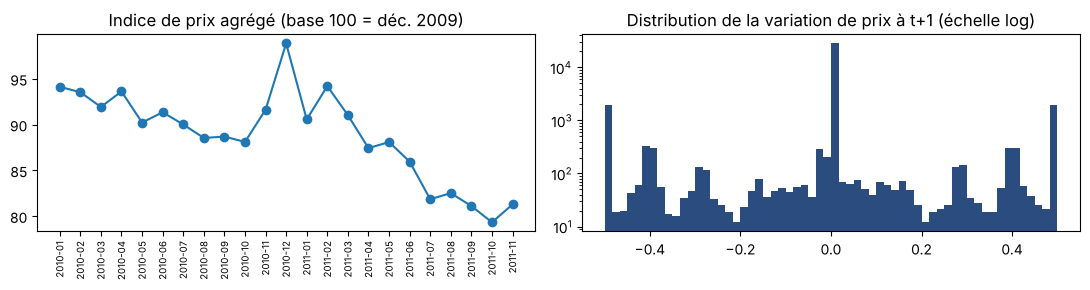

In [ ]:
# ===== THÈME : Anticipations d'inflation — jeu « Online Retail II » (boutique en ligne britannique, 2009-2011) =====
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Ellipse, Circle, Polygon
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
GRAINE = 42

chemins = ['online_retail_II_1.xlsx', 'online_retail_II.xlsx', '/content/online_retail_II_1.xlsx', '/mnt/user-data/uploads/online_retail_II_1.xlsx']
CHEMIN = next(p for p in chemins if os.path.exists(p))
brut = pd.concat(pd.read_excel(CHEMIN, sheet_name=None).values(), ignore_index=True)   # 2 feuilles : 2009-2010 et 2010-2011
print('Lignes brutes :', brut.shape)

# 1) Nettoyage : ventes réelles de produits (on retire annulations « C... », prix/quantités <= 0, codes de frais : POST, DOT, M, BANK CHARGES...)
d = brut[(brut.Price > 0) & (brut.Quantity > 0) & (~brut.Invoice.astype(str).str.startswith('C'))]
d = d[d.StockCode.astype(str).str.match(r'^\d{5}')]
d = d[d.InvoiceDate < '2011-12-01']                       # décembre 2011 est incomplet (données jusqu'au 9/12)
d = d.assign(mois=d.InvoiceDate.dt.to_period('M'))
print('Lignes retenues :', d.shape, '| produits :', d.StockCode.nunique(), '| mois :', d.mois.min(), '→', d.mois.max())

# 2) Panel produit × mois : prix médian (robuste aux remises ponctuelles), quantité, nombre de commandes
g = d.groupby(['StockCode', 'mois']).agg(prix=('Price', 'median'), qte=('Quantity', 'sum'), cmd=('Invoice', 'nunique')).reset_index()
calendrier = pd.period_range(d.mois.min(), d.mois.max(), freq='M')
P = np.log(g.pivot(index='mois', columns='StockCode', values='prix').reindex(calendrier))   # log-prix
Q = np.log(g.pivot(index='mois', columns='StockCode', values='qte').reindex(calendrier))
N = np.log(g.pivot(index='mois', columns='StockCode', values='cmd').reindex(calendrier))
dP, dQ, dN = P.diff(), Q.diff(), N.diff()

# 3) Variable à prédire (« anticipation ») : variation du log-prix entre t et t+1 ; variables explicatives : information connue en t
blocs = []
for t in range(3, len(calendrier) - 1):
    blocs.append(pd.DataFrame({
        'produit': P.columns, 'mois': calendrier[t],
        'cible': dP.iloc[t + 1].values,                                   # inflation du produit au mois suivant
        'var_prix_t': dP.iloc[t].values, 'var_prix_t1': dP.iloc[t - 1].values, 'var_prix_t2': dP.iloc[t - 2].values,
        'var_qte_t': dQ.iloc[t].values, 'var_cmd_t': dN.iloc[t].values,
        'niveau_prix': P.iloc[t].values, 'ecart_moy3': (P.iloc[t] - P.iloc[t - 3:t].mean()).values,
        'log_qte': Q.iloc[t].values, 'num_mois': calendrier[t].month}))
D = pd.concat(blocs, ignore_index=True).dropna().reset_index(drop=True)
part_bornee = (D.cible.abs() > 0.5).mean()
D['cible'] = D.cible.clip(-0.5, 0.5)                                       # bornage : variations > ±50 % = erreurs de saisie / lots
for m in range(2, 13): D[f'mois_{m}'] = (D.num_mois == m).astype(int)      # indicatrices de mois (janvier = référence)
D = D.drop(columns='num_mois')

VARIABLES = [c for c in D.columns if c not in ('produit', 'mois', 'cible')]
coupure = pd.Period('2011-03', 'M')                                        # découpage TEMPOREL : on entraîne sur le passé, on teste sur le futur
ent, test = D[D.mois <= coupure], D[D.mois > coupure]
X_ent, y_ent, X_test, y_test = ent[VARIABLES], ent.cible, test[VARIABLES], test.cible
print(f'Observations : {len(D)} | entraînement : {len(ent)} ({ent.mois.min()}→{ent.mois.max()}) | test : {len(test)} ({test.mois.min()}→{test.mois.max()})')
print(f'Part de cibles bornées à ±50 % : {part_bornee:.1%} | part de prix inchangés au mois suivant : {(D.cible == 0).mean():.1%}')
display(D.head())

# --- Fonctions réutilisées par les sections 1, 2 et 3 ---
def evaluer(nom, modele):
    p = modele.predict(X_test)
    return {'modèle': nom, 'RMSE': mean_squared_error(y_test, p) ** .5, 'MAE': mean_absolute_error(y_test, p), 'R²': r2_score(y_test, p)}

def cv_rmse(modele, colonnes=None):
    """RMSE en validation croisée TEMPORELLE (5 plis à origine glissante) sur l'ENTRAÎNEMENT uniquement."""
    X = X_ent if colonnes is None else X_ent[colonnes]
    s = -cross_val_score(modele, X, y_ent, cv=TimeSeriesSplit(5), scoring='neg_root_mean_squared_error')
    return s.mean(), s.std()

def tracer_variation(t, nom, log=False):
    plt.figure(figsize=(5.5, 3)); plt.errorbar(t['valeur'].astype(str), t['RMSE CV'], yerr=t['écart-type'], marker='o', capsize=3)
    plt.xlabel(nom); plt.ylabel('RMSE (CV temporelle)'); plt.title(f'Effet de {nom}'); plt.xticks(rotation=30); plt.show()

def inflation_agregee(pred):
    """Inflation moyenne par mois : observée vs anticipée par le modèle (moyenne sur tous les produits)."""
    t = test.assign(prevue=pred).groupby('mois').agg(observée=('cible', 'mean'), anticipée=('prevue', 'mean'))
    t.index = t.index + 1                                                  # le mois t explique l'inflation du mois t+1
    return t

base_zero = {'modèle': 'Référence : inflation nulle', 'RMSE': mean_squared_error(y_test, np.zeros(len(y_test))) ** .5, 'MAE': mean_absolute_error(y_test, np.zeros(len(y_test))), 'R²': r2_score(y_test, np.zeros(len(y_test)))}
base_pers = {'modèle': 'Référence : persistance', **{k: f(y_test, X_test.var_prix_t) for k, f in [('RMSE', lambda a, b: mean_squared_error(a, b) ** .5), ('MAE', mean_absolute_error), ('R²', r2_score)]}}

# Indice de prix agrégé (base 100) = moyenne des variations de log-prix sur les produits vendus deux mois de suite
infl_mensuelle = dP.mean(axis=1).iloc[1:]
indice = 100 * np.exp(infl_mensuelle.cumsum())
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].plot(indice.index.astype(str), indice.values, marker='o'); ax[0].set_title('Indice de prix agrégé (base 100 = déc. 2009)'); ax[0].tick_params(axis='x', rotation=90, labelsize=7)
ax[1].hist(D.cible, bins=60, color='#2b4c7e'); ax[1].set_yscale('log'); ax[1].set_title('Distribution de la variation de prix à t+1 (échelle log)'); plt.tight_layout(); plt.show()


## 1. Régression linéaire

**Question ciblée (Partie B) :** Expliquez pourquoi une relation linéaire entre les variables médicales et la cible peut être insuffisante.

**Thème : anticipations d'inflation** — la même question se pose pour les variables de marché et la variation de prix du mois suivant.

### Présentation
La régression linéaire modélise la cible par une **somme pondérée** des variables : ŷ = β₀ + β₁x₁ + … + β_p x_p. Les coefficients sont choisis par les **moindres carrés ordinaires** (MCO) : on minimise Σ (yᵢ − ŷᵢ)², ce qui a une solution fermée β = (XᵀX)⁻¹Xᵀy. Elle suppose une relation additive et linéaire, des erreurs d'espérance nulle, de variance constante et peu de colinéarité. Atouts : rapide, **interprétable** (un coefficient = effet d'une variable « toutes choses égales par ailleurs »), sans hyperparamètre à régler. Limites : sensible aux variables corrélées et aux valeurs extrêmes, et incapable de représenter une relation courbe ou des interactions.

### Réponse à la question ciblée
Une relation linéaire peut être insuffisante parce que le monde réel est rarement une droite : (1) **non-linéarité** — l'effet d'une variable change avec son niveau (seuils, saturation) ; (2) **interactions** — l'effet d'une variable dépend d'une autre (un modèle additif ne peut pas l'exprimer) ; (3) **erreurs non gaussiennes ou hétéroscédastiques** — les hypothèses des MCO sont violées, les coefficients restent calculables mais leur interprétation et les prévisions deviennent moins fiables ; (4) **variables corrélées ou omises** — les coefficients deviennent instables. Les graphiques ci-dessous (thème inflation) illustrent les points 1 et 3 ; le code de référence du TP (jeu Diabetes) suit immédiatement.

In [ ]:
from sklearn.linear_model import LinearRegression
modele=LinearRegression().fit(Xr_ent,yr_ent)
pred=modele.predict(Xr_test)
print('RMSE:',mean_squared_error(yr_test,pred)**.5,'R²:',r2_score(yr_test,pred))

RMSE: 53.369566710321955 R²: 0.4849058889476756


#### Schéma original — de l'information du mois *t* à l'anticipation du mois *t+1*

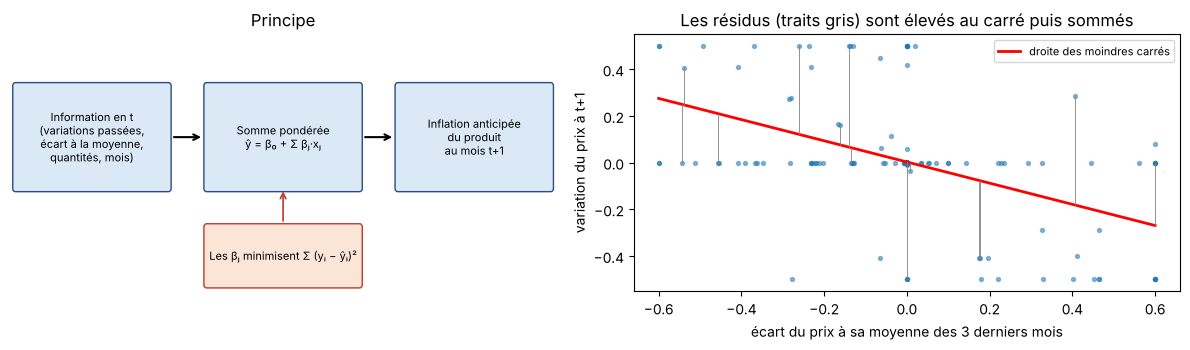

In [ ]:
# Schéma original — Régression linéaire : de l'information du mois t à l'anticipation d'inflation du mois t+1
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
a = ax[0]; a.axis('off'); a.set_xlim(0, 10); a.set_ylim(0, 4)
boites = [(0.1, 'Information en t\n(variations passées,\nécart à la moyenne,\nquantités, mois)'), (3.6, 'Somme pondérée\nŷ = β₀ + Σ βⱼ·xⱼ'), (7.1, 'Inflation anticipée\ndu produit\nau mois t+1')]
for x, txt in boites:
    a.add_patch(FancyBboxPatch((x, 1.6), 2.8, 1.6, boxstyle='round,pad=0.05', fc='#dbe9f6', ec='#2b4c7e')); a.text(x + 1.4, 2.4, txt, ha='center', va='center', fontsize=8)
for x in (2.95, 6.45): a.annotate('', xy=(x + 0.6, 2.4), xytext=(x, 2.4), arrowprops=dict(arrowstyle='->', lw=1.5))
a.add_patch(FancyBboxPatch((3.6, 0.1), 2.8, 0.9, boxstyle='round,pad=0.05', fc='#fbe5d6', ec='#c0392b')); a.text(5, 0.55, 'Les βⱼ minimisent Σ (yᵢ − ŷᵢ)²', ha='center', va='center', fontsize=8)
a.annotate('', xy=(5, 1.6), xytext=(5, 1.05), arrowprops=dict(arrowstyle='->', lw=1.2, color='#c0392b')); a.set_title('Principe')
b = ax[1]; ech = ent.sample(250, random_state=GRAINE); x = ech.ecart_moy3.clip(-.6, .6); y = ech.cible
mod = np.polyfit(x, y, 1); b.scatter(x, y, s=8, alpha=.5); xs = np.linspace(-.6, .6, 50); b.plot(xs, np.polyval(mod, xs), 'r-', lw=2, label='droite des moindres carrés')
for xi, yi in list(zip(x, y))[:35]: b.plot([xi, xi], [yi, np.polyval(mod, xi)], color='gray', lw=.6)
b.set_xlabel('écart du prix à sa moyenne des 3 derniers mois'); b.set_ylabel('variation du prix à t+1'); b.legend(fontsize=8); b.set_title('Les résidus (traits gris) sont élevés au carré puis sommés'); plt.tight_layout(); plt.show()


#### Deux cas d'usage
1. **Gestion des prix d'un commerçant** : anticiper la variation du prix de chaque référence le mois suivant pour planifier les achats auprès des fournisseurs et la politique de marge. Les coefficients indiquent *quels signaux* (prix au-dessus de sa moyenne, saison de Noël…) font monter ou baisser les prix.
2. **Suivi macro-économique** : un institut ou une banque centrale relie les anticipations d'inflation des ménages (enquêtes) à des variables simples (inflation passée, prix de l'énergie, taux) ; la lisibilité des coefficients permet d'expliquer la prévision.

#### Application au thème (code)

                               RMSE     MAE      R²
modèle                                             
Référence : inflation nulle  0.1836  0.0766 -0.0001
Référence : persistance      0.3957  0.1759 -3.6445
Régression linéaire          0.1688  0.0940  0.1546
Effet d'1 écart-type de chaque variable (10 plus forts) :
              effet
ecart_moy3  -0.0553
var_prix_t  -0.0447
var_prix_t1 -0.0220
mois_11      0.0185
log_qte      0.0126
var_prix_t2 -0.0117
var_qte_t   -0.0114
mois_12     -0.0103
mois_2      -0.0072
mois_3      -0.0071
Corrélation inflation agrégée observée / anticipée : 0.64
Part de produits dont le prix ne change pas (test) : 79.4% | part des prédictions exactement nulles : 0.0%

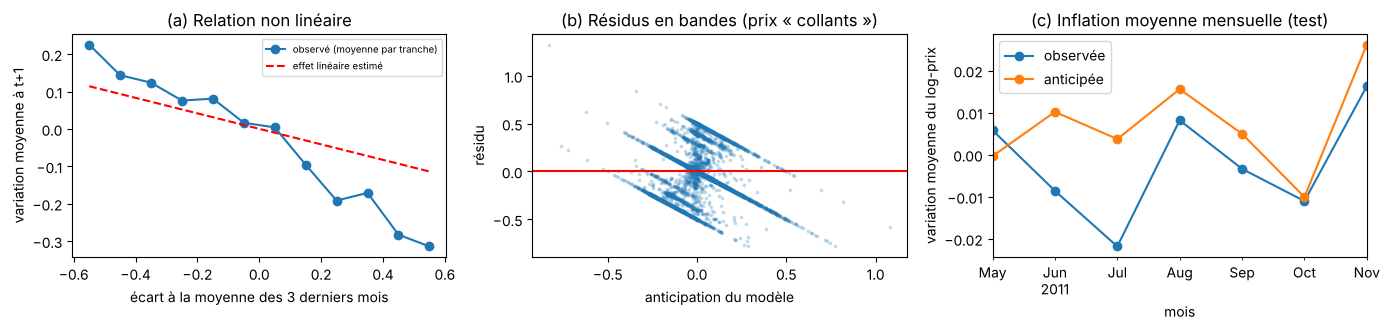

In [ ]:
# Régression linéaire appliquée aux anticipations d'inflation
modele_lin = LinearRegression().fit(X_ent, y_ent)
pred_lin = modele_lin.predict(X_test)
res_lin = pd.DataFrame([base_zero, base_pers, evaluer('Régression linéaire', modele_lin)]).set_index('modèle')
display(res_lin.round(4))

# Coefficients comparables : effet d'un écart-type de chaque variable sur la variation de prix anticipée
coef = pd.Series(modele_lin.coef_ * X_ent.std().values, index=VARIABLES).sort_values(key=abs, ascending=False)
print('Effet d\'1 écart-type de chaque variable (10 plus forts) :'); display(coef.head(10).round(4).to_frame('effet'))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
# (a) La relation réelle n'est pas une droite : variation moyenne observée par tranche d'écart à la moyenne (entraînement)
bornes = np.linspace(-.6, .6, 13); tr = pd.cut(ent.ecart_moy3.clip(-.59, .59), bornes)
moy = ent.groupby(tr, observed=True).cible.agg(['mean', 'count']); centres = [i.mid for i in moy.index]
ax[0].plot(centres, moy['mean'], 'o-', label='observé (moyenne par tranche)')
ax[0].plot(centres, modele_lin.intercept_ + (modele_lin.coef_[VARIABLES.index('ecart_moy3')] * np.array(centres)) + (X_ent.drop(columns='ecart_moy3').mean() * pd.Series(modele_lin.coef_, VARIABLES).drop('ecart_moy3')).sum(), 'r--', label='effet linéaire estimé')
ax[0].set_xlabel('écart à la moyenne des 3 derniers mois'); ax[0].set_ylabel('variation moyenne à t+1'); ax[0].legend(fontsize=7); ax[0].set_title('(a) Relation non linéaire')
# (b) Résidus : la masse de produits dont le prix ne bouge pas crée une structure que la droite ne capte pas
ax[1].scatter(pred_lin, y_test - pred_lin, s=3, alpha=.2); ax[1].axhline(0, color='r'); ax[1].set_xlabel('anticipation du modèle'); ax[1].set_ylabel('résidu'); ax[1].set_title('(b) Résidus en bandes (prix « collants »)')
# (c) Au niveau agrégé : inflation moyenne observée vs anticipée
agr = inflation_agregee(pred_lin); agr.plot(ax=ax[2], marker='o'); ax[2].set_title('(c) Inflation moyenne mensuelle (test)'); ax[2].set_xlabel('mois'); ax[2].set_ylabel('variation moyenne du log-prix')
plt.tight_layout(); plt.show()
print('Corrélation inflation agrégée observée / anticipée :', round(agr.corr().iloc[0, 1], 3))
print('Part de produits dont le prix ne change pas (test) :', f'{(y_test == 0).mean():.1%}', '| part des prédictions exactement nulles :', f'{(np.abs(pred_lin) < 1e-9).mean():.1%}')


#### Analyse de la sortie
- **Performance** : sur le test (avril → octobre 2011), le RMSE est de **0,169** contre **0,184** pour « inflation nulle » (≈ −8 %), et le R² vaut **0,155** : le modèle explique environ 15 % de la variance de la variation de prix du mois suivant — modeste, mais réel. La « persistance » échoue complètement (R² = −3,6) : les prix **reviennent vers leur moyenne** au lieu de prolonger la variation précédente.
- **Coefficients** (effet d'un écart-type) : `ecart_moy3` ≈ **−0,055** et `var_prix_t` ≈ **−0,045** — un prix qui vient de monter au-dessus de sa moyenne récente a tendance à redescendre (fin de promotion ou de hausse temporaire) ; `mois_11` ≈ **+0,019** — les produits observés en novembre augmentent en décembre (saisonnalité de Noël).
- **MAE** : 0,094, *moins bonne* que « inflation nulle » (0,077). Raison : 79 % des prix ne bougent pas, alors que la droite prédit toujours une petite variation non nulle (0 % de prévisions exactement nulles) ; le gain vient des produits dont le prix bouge beaucoup.
- **Graphique (a)** : la courbe observée est plus raide que la droite dans les queues — un grand écart se corrige presque entièrement, un petit écart peu : relation **non linéaire**. **Graphique (b)** : les résidus forment des bandes diagonales (prix « collants » : y = 0 donne un résidu égal à −ŷ) : erreurs non gaussiennes. **Graphique (c)** : au niveau agrégé, la corrélation entre inflation moyenne observée et anticipée est de **0,64** sur 7 mois (peu de points : prudence), avec une sur-anticipation en juin-juillet.

→ Conclusion : la droite capte le *sens* du retour à la moyenne et la saisonnalité, mais elle est limitée par la nature du phénomène (prix rigides, effets de seuil), ce qui motive les modèles non linéaires des sections 4 à 7.

#### Variation d'un hyperparamètre (validation croisée temporelle sur l'entraînement)
`LinearRegression` n'a presque pas d'hyperparamètre : on fait varier `positive` (coefficients forcés ≥ 0), puis la **taille du jeu de variables** (choix de modélisation).

           valeur  RMSE CV  écart-type
0  positive=False   0.1729      0.0218
1   positive=True   0.1950      0.0262
                  valeur  RMSE CV  écart-type
0    1 var. (var_prix_t)   0.1807      0.0240
1           + écart_moy3   0.1733      0.0223
2  + retards & quantités   0.1727      0.0215
3        + mois (toutes)   0.1729      0.0218

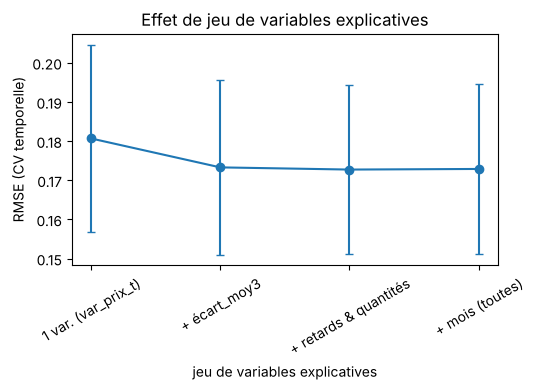

In [ ]:
# Variation d'un hyperparamètre : LinearRegression(positive=...) puis taille du jeu de variables — validation croisée temporelle sur l'ENTRAÎNEMENT
lignes = []
for v in (False, True):
    m, s = cv_rmse(LinearRegression(positive=v)); lignes.append((f'positive={v}', m, s))
t1 = pd.DataFrame(lignes, columns=['valeur', 'RMSE CV', 'écart-type']); display(t1.round(4))

ensembles = {'1 var. (var_prix_t)': ['var_prix_t'], '+ écart_moy3': ['var_prix_t', 'ecart_moy3'], '+ retards & quantités': VARIABLES[:8], '+ mois (toutes)': VARIABLES}
lignes = []
for nom, cols in ensembles.items():
    m, s = cv_rmse(LinearRegression(), cols); lignes.append((nom, m, s))
t2 = pd.DataFrame(lignes, columns=['valeur', 'RMSE CV', 'écart-type']); display(t2.round(4)); tracer_variation(t2, 'jeu de variables explicatives')


**Lecture.** `positive=True` dégrade nettement le RMSE (0,195 contre 0,173) : les effets importants sont **négatifs** (retour à la moyenne), forcer des coefficients positifs est donc une mauvaise contrainte. Ajouter `ecart_moy3` à `var_prix_t` améliore de 0,181 à 0,173 (≈ −4 %) ; les retards, quantités et mois n'apportent presque plus rien (0,1727 → 0,1729). L'écart-type entre plis (≈ 0,022) est bien supérieur à ces dernières différences : on ne les interprète pas.

## 2. Ridge

**Question ciblée (Partie B) :** Que se passe-t-il lorsque la pénalisation L2 devient très forte ?

**Thème : anticipations d'inflation.**

### Présentation
Ridge est une régression linéaire dont on **pénalise la taille des coefficients** : on minimise Σ (yᵢ − ŷᵢ)² + α Σ βⱼ², soit β = (XᵀX + αI)⁻¹Xᵀy. Le paramètre α ≥ 0 règle le compromis biais / variance : α = 0 redonne les MCO ; plus α est grand, plus les coefficients sont « rétractés » vers 0. La pénalité s'applique aux coefficients, donc les variables doivent être **standardisées** (d'où `StandardScaler` dans le pipeline) et l'ordonnée à l'origine n'est pas pénalisée. Ridge stabilise les coefficients quand les variables sont **corrélées** (ici : les variations de prix retardées), mais ne supprime aucune variable.

### Réponse à la question ciblée
Quand α devient très grand, la pénalité écrase le terme d'erreur : **tous les coefficients tendent vers 0** (sans jamais être exactement nuls) et le modèle devient une **constante égale à la moyenne de la cible d'entraînement** : prévisions identiques pour tous, R² → 0, RMSE → écart-type de la cible. C'est le **sous-apprentissage** (biais maximal, variance nulle). Le tableau de l'analyse le vérifie sur nos données.

In [ ]:
from sklearn.linear_model import Ridge
modele=make_pipeline(StandardScaler(),Ridge(alpha=25.)).fit(Xr_ent,yr_ent)
print('MAE:',mean_absolute_error(yr_test,modele.predict(Xr_test)))

MAE: 41.49082128021844


#### Schéma original — disque L2 (contrainte) et chemin de régularisation

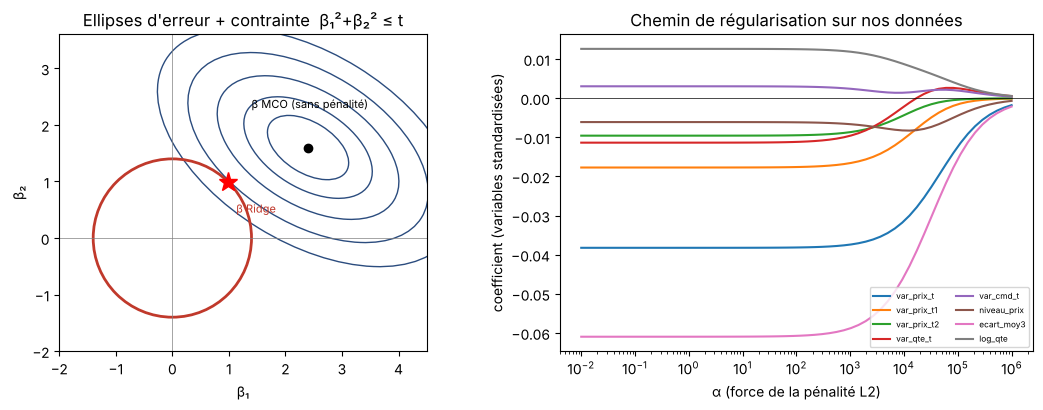

In [ ]:
# Schéma original — Ridge : le disque L2 « ramène » les coefficients vers zéro sans les annuler
def contour(ax, centre, A, niveaux, couleur='#2b4c7e'):
    vals, vecs = np.linalg.eigh(A)
    for k in niveaux:
        ax.add_patch(Ellipse(centre, 2 * np.sqrt(k / vals[0]), 2 * np.sqrt(k / vals[1]), angle=np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0])), fill=False, ec=couleur, lw=1))
A = np.array([[1.0, .6], [.6, 1.6]]); b_mco = np.array([2.4, 1.6])
th = np.linspace(0, 2 * np.pi, 2000); cercle = 1.4 * np.c_[np.cos(th), np.sin(th)]
perte = lambda B: np.einsum('ni,ij,nj->n', B - b_mco, A, B - b_mco); b_ridge = cercle[perte(cercle).argmin()]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
a = ax[0]; contour(a, b_mco, A, [.4, 1, 2, 3.5, 5.5]); a.add_patch(Circle((0, 0), 1.4, fill=False, ec='#c0392b', lw=2))
a.plot(*b_mco, 'ko'); a.annotate('β MCO (sans pénalité)', b_mco, (b_mco[0] - 1.0, b_mco[1] + .7), fontsize=8)
a.plot(*b_ridge, 'r*', ms=14); a.annotate('β Ridge', b_ridge, (b_ridge[0] + .15, b_ridge[1] - .55), fontsize=8, color='#c0392b')
a.axhline(0, color='gray', lw=.5); a.axvline(0, color='gray', lw=.5); a.set_xlim(-2, 4.5); a.set_ylim(-2, 3.6); a.set_aspect('equal'); a.set_xlabel('β₁'); a.set_ylabel('β₂'); a.set_title('Ellipses d\'erreur + contrainte  β₁²+β₂² ≤ t')
b = ax[1]; alphas = np.logspace(-2, 6, 60)
coefs = np.array([Ridge(alpha=al).fit(StandardScaler().fit_transform(X_ent), y_ent).coef_ for al in alphas])
[b.semilogx(alphas, coefs[:, j], label=VARIABLES[j]) for j in range(8)]; b.legend(fontsize=6, ncol=2); b.axhline(0, color='k', lw=.5); b.set_xlabel('α (force de la pénalité L2)'); b.set_ylabel('coefficient (variables standardisées)'); b.set_title('Chemin de régularisation sur nos données')
plt.tight_layout(); plt.show()


#### Deux cas d'usage
1. **Prévision d'inflation avec beaucoup d'indicateurs corrélés** (prix retardés, matières premières, taux de change, salaires) : Ridge conserve tous les indicateurs mais empêche les coefficients de diverger quand ils se recoupent.
2. **Tarification dynamique** : prédire la variation de prix d'un produit à partir de ses prix passés et de ses ventes, variables fortement liées entre elles ; la pénalité L2 rend les prévisions plus stables d'un mois à l'autre.

#### Application au thème (code)

In [ ]:
# Ridge appliqué aux anticipations d'inflation (avec standardisation : la pénalité doit traiter toutes les variables de la même façon)
alpha_ref = 25.
modele_ridge = make_pipeline(StandardScaler(), Ridge(alpha=alpha_ref)).fit(X_ent, y_ent)
res_ridge = pd.DataFrame([evaluer(f'Ridge (α={alpha_ref:g})', modele_ridge), evaluer('Régression linéaire', modele_lin)]).set_index('modèle'); display(res_ridge.round(4))

# Que se passe-t-il quand α devient très fort ?
lignes = []
for al in [0.01, 1, 25, 1e3, 1e4, 1e5, 1e6, 1e8]:
    m = make_pipeline(StandardScaler(), Ridge(alpha=al)).fit(X_ent, y_ent); p = m.predict(X_test); c = m[-1].coef_
    lignes.append((al, np.abs(c).max(), np.linalg.norm(c), np.std(p), r2_score(y_test, p), mean_squared_error(y_test, p) ** .5))
t_ex = pd.DataFrame(lignes, columns=['α', '|coef| max', 'norme L2 des coef.', 'écart-type des prédictions', 'R² test', 'RMSE test']); display(t_ex.round(5))
print('Moyenne de la cible (entraînement) =', round(y_ent.mean(), 5), '| écart-type de la cible (test) =', round(y_test.std(), 4))


                       RMSE    MAE      R²
modèle                                    
Ridge (α=25)         0.1688  0.094  0.1547
Régression linéaire  0.1688  0.094  0.1546
              α  |coef| max  norme L2 des coef.  écart-type des prédictions  R² test  RMSE test
0  1.000000e-02     0.06096             0.08121                     0.09674  0.15463    0.16880
1  1.000000e+00     0.06096             0.08121                     0.09674  0.15463    0.16880
2  2.500000e+01     0.06090             0.08113                     0.09667  0.15474    0.16879
3  1.000000e+03     0.05882             0.07805                     0.09404  0.15857    0.16841
4  1.000000e+04     0.04555             0.06050                     0.07653  0.17015    0.16725
5  1.000000e+05     0.01555             0.02169                     0.02961  0.10401    0.17378
6  1.000000e+06     0.00213             0.00308                     0.00430  0.01784    0.18195
7  1.000000e+08     0.00002             0.00003             

#### Analyse de la sortie
- Avec α = 25, Ridge est **identique à la régression linéaire** (RMSE 0,1688, R² 0,155). Ce n'est pas un bogue : on a 23 714 observations pour 19 variables, et la pénalité de scikit-learn s'ajoute à une somme d'erreurs (non divisée par n) ; il faut donc un α de l'ordre de 10³-10⁴ pour qu'elle pèse vraiment. Les coefficients de la section 1 (ex. `ecart_moy3`) sont d'ailleurs déjà bien estimés.
- **Réponse chiffrée à la question** : α = 10⁴ → coefficient maximal 0,046 (0,061 à α faible) ; α = 10⁶ → 0,002 ; **α = 10⁸ → 0,00002**, écart-type des prévisions 0,00005, **R² test = 0,00004** et RMSE 0,1836, c'est-à-dire exactement l'écart-type de la cible : le modèle prédit la moyenne (≈ 0,0005) pour tout le monde.
- Un α *modéré* peut aider : sur le test, α = 10⁴ donne un R² de 0,170 (RMSE 0,1673) contre 0,155 sans pénalité — le rétrécissement réduit la variance. Mais ce gain n'est pas sélectionné par la validation croisée (voir ci-dessous) ; on ne règle pas α sur le test.

#### Variation d'un hyperparamètre (α, validation croisée temporelle sur l'entraînement)

       valeur  RMSE CV  écart-type
0        0.01  0.17282     0.02176
1        1.00  0.17282     0.02176
2       10.00  0.17282     0.02176
3      100.00  0.17282     0.02176
4     1000.00  0.17293     0.02163
5    10000.00  0.17610     0.02050
6   100000.00  0.18879     0.02338
7  1000000.00  0.19547     0.02630
α retenu en validation croisée : 100.0
                 RMSE     MAE      R²
modèle                               
Ridge (α=100)  0.1688  0.0939  0.1551

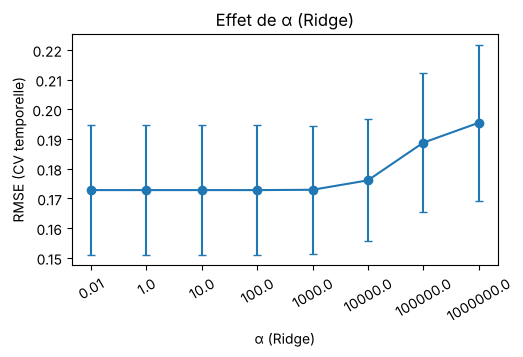

In [ ]:
# Variation d'un hyperparamètre : α de Ridge — validation croisée temporelle sur l'ENTRAÎNEMENT (le test n'est pas utilisé)
alphas = [0.01, 1, 10, 100, 1e3, 1e4, 1e5, 1e6]
lignes = []
for al in alphas:
    m, s = cv_rmse(make_pipeline(StandardScaler(), Ridge(alpha=al))); lignes.append((al, m, s))
t_r = pd.DataFrame(lignes, columns=['valeur', 'RMSE CV', 'écart-type']); display(t_r.round(5)); tracer_variation(t_r, 'α (Ridge)')
alpha_star = t_r.loc[t_r['RMSE CV'].idxmin(), 'valeur']; print('α retenu en validation croisée :', alpha_star)
modele_ridge_cv = make_pipeline(StandardScaler(), Ridge(alpha=alpha_star)).fit(X_ent, y_ent)
display(pd.DataFrame([evaluer(f'Ridge (α={alpha_star:g})', modele_ridge_cv)]).set_index('modèle').round(4))


**Lecture.** Le RMSE de validation croisée est **plat** (0,1728) de α = 0,01 à 100, puis monte : 0,1761 (10⁴), 0,1888 (10⁵), 0,1955 (10⁶) — signature du sous-apprentissage quand la pénalité devient trop forte. L'α retenu (100) n'est qu'un ex æquo de ce plateau : le test donne RMSE 0,1688 et R² 0,155, comme les MCO. Ici, **n ≫ p**, donc Ridge apporte peu ; son intérêt apparaît quand les variables sont nombreuses ou fortement colinéaires.

## 3. Lasso

**Question ciblée (Partie B) :** Comment la pénalisation L1 sélectionne-t-elle des variables ?

**Thème : anticipations d'inflation.**

### Présentation
Lasso pénalise la **somme des valeurs absolues** des coefficients : on minimise (1/2n) Σ (yᵢ − ŷᵢ)² + α Σ |βⱼ|. Il n'y a pas de formule fermée ; scikit-learn utilise la descente de coordonnées, où chaque coefficient est mis à jour par un **seuillage doux** : β_j ← signe(ρ_j)·max(|ρ_j| − α, 0) / (norme de la variable), avec ρ_j la corrélation de la variable avec le résidu partiel. Atouts : modèle **parcimonieux** et lisible, sélection de variables intégrée. Limites : instable si des variables sont très corrélées (il en garde une au hasard), biais sur les coefficients conservés, et variables à standardiser.

### Réponse à la question ciblée
La contrainte L1 (|β₁| + |β₂| ≤ t) a la forme d'un **losange dont les pointes sont sur les axes** : les courbes de niveau de l'erreur touchent souvent le losange à une pointe, où un coefficient est **exactement nul** (schéma ci-dessous). Algébriquement, le seuillage doux met à 0 toute variable dont la corrélation avec le résidu est inférieure à α. En augmentant α, les variables sortent du modèle **une à une** — les moins utiles d'abord ; la dernière à rester est la plus informative. Contrairement à Ridge (qui rétrécit sans annuler), Lasso **supprime** des variables.

In [ ]:
from sklearn.linear_model import Lasso
modele=make_pipeline(StandardScaler(),Lasso(alpha=3.,max_iter=15000)).fit(Xr_ent,yr_ent)
print('R²:',r2_score(yr_test,modele.predict(Xr_test)))

R²: 0.5013056660042327


#### Schéma original — losange L1 et sélection de variables

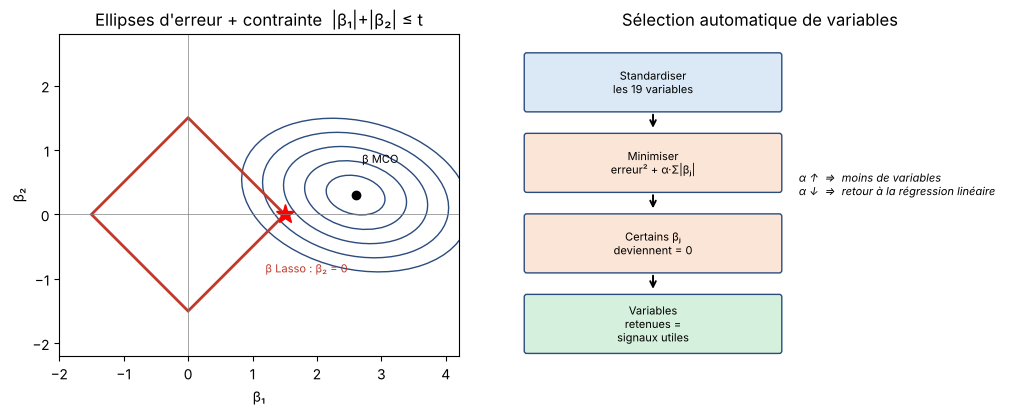

In [ ]:
# Schéma original — Lasso : le losange L1 a des « pointes » sur les axes, donc des coefficients exactement nuls
A = np.array([[1.0, .3], [.3, 2.2]]); b_mco = np.array([2.6, .3])
th = np.linspace(0, 2 * np.pi, 4001); r = 1.5
losange = np.array([[x, y] for x, y in zip(r * np.cos(th) / (abs(np.cos(th)) + abs(np.sin(th))), r * np.sin(th) / (abs(np.cos(th)) + abs(np.sin(th))))])
perte = lambda B: np.einsum('ni,ij,nj->n', B - b_mco, A, B - b_mco); b_lasso = losange[perte(losange).argmin()]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
a = ax[0]; contour(a, b_mco, A, [.2, .6, 1.2, 2, 3]); a.add_patch(Polygon([(r, 0), (0, r), (-r, 0), (0, -r)], fill=False, ec='#c0392b', lw=2))
a.plot(*b_mco, 'ko'); a.annotate('β MCO', b_mco, (b_mco[0] + .1, b_mco[1] + .5), fontsize=8)
a.plot(*b_lasso, 'r*', ms=14); a.annotate('β Lasso : β₂ = 0', b_lasso, (b_lasso[0] - .3, b_lasso[1] - .9), fontsize=8, color='#c0392b')
a.axhline(0, color='gray', lw=.5); a.axvline(0, color='gray', lw=.5); a.set_xlim(-2, 4.2); a.set_ylim(-2.2, 2.8); a.set_aspect('equal'); a.set_xlabel('β₁'); a.set_ylabel('β₂'); a.set_title('Ellipses d\'erreur + contrainte  |β₁|+|β₂| ≤ t')
b = ax[1]; b.axis('off'); b.set_xlim(0, 10); b.set_ylim(0, 6)
etapes = ['Standardiser\nles 19 variables', 'Minimiser\nerreur² + α·Σ|βⱼ|', 'Certains βⱼ\ndeviennent = 0', 'Variables\nretenues =\nsignaux utiles']
for i, e in enumerate(etapes):
    b.add_patch(FancyBboxPatch((0.2, 4.6 - i * 1.5), 5.2, 1.0, boxstyle='round,pad=0.05', fc=['#dbe9f6', '#fbe5d6', '#fbe5d6', '#d5f0dc'][i], ec='#2b4c7e')); b.text(2.8, 5.1 - i * 1.5, e, ha='center', va='center', fontsize=8)
    if i < 3: b.annotate('', xy=(2.8, 4.55 - i * 1.5 - .35), xytext=(2.8, 4.55 - i * 1.5), arrowprops=dict(arrowstyle='->', lw=1.4))
b.text(5.8, 3.2, 'α ↑  ⇒  moins de variables\nα ↓  ⇒  retour à la régression linéaire', fontsize=8, style='italic', va='center'); b.set_title('Sélection automatique de variables')
plt.tight_layout(); plt.show()


#### Deux cas d'usage
1. **Repérer les vrais déterminants des anticipations d'inflation** parmi des dizaines d'indicateurs candidats (enquêtes, énergie, salaires, taux, change) : les coefficients non nuls forment la liste des signaux utiles, facile à présenter à un décideur.
2. **Identifier les produits ou les périodes sensibles** : parmi des indicatrices de catégories et de mois, Lasso retient celles qui ont un effet réel sur la variation de prix (ici, certains mois) et élimine les autres.

#### Application au thème (code)

                   RMSE     MAE      R²
modèle                                 
Lasso (α=0.002)  0.1683  0.0913  0.1597
Variables retenues : 13 sur 19 | éliminées (coef. = 0) : 6
             coefficient (standardisé)
ecart_moy3                     -0.0833
mois_11                         0.0206
log_qte                         0.0100
var_prix_t                     -0.0097
var_qte_t                      -0.0056
niveau_prix                    -0.0055
mois_12                        -0.0052
mois_10                         0.0037
mois_2                         -0.0019
mois_9                         -0.0016
mois_5                          0.0012
mois_4                         -0.0006
mois_3                         -0.0005

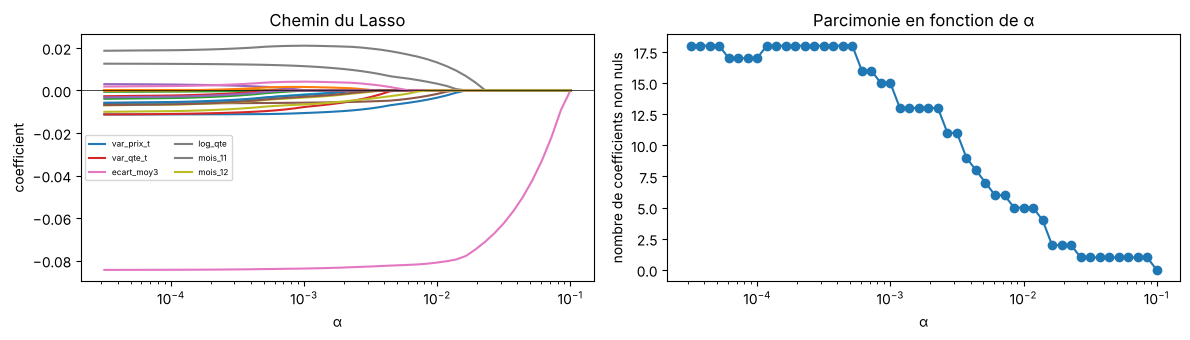

In [ ]:
# Lasso appliqué aux anticipations d'inflation
alpha_ref = 0.002
modele_lasso = make_pipeline(StandardScaler(), Lasso(alpha=alpha_ref, max_iter=15000)).fit(X_ent, y_ent)
res_lasso = pd.DataFrame([evaluer(f'Lasso (α={alpha_ref:g})', modele_lasso)]).set_index('modèle'); display(res_lasso.round(4))
c = pd.Series(modele_lasso[-1].coef_, index=VARIABLES)
print(f'Variables retenues : {(c != 0).sum()} sur {len(c)} | éliminées (coef. = 0) : {(c == 0).sum()}')
display(c[c != 0].sort_values(key=abs, ascending=False).round(4).to_frame('coefficient (standardisé)'))

# Chemin de régularisation : à quel α chaque variable disparaît-elle ?
alphas_ch = np.logspace(-4.5, -1, 50)
chem = np.array([Lasso(alpha=al, max_iter=20000).fit(StandardScaler().fit_transform(X_ent), y_ent).coef_ for al in alphas_ch])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for j, v in enumerate(VARIABLES): ax[0].semilogx(alphas_ch, chem[:, j], label=v if np.abs(chem[:, j]).max() > .01 else None)
ax[0].axhline(0, color='k', lw=.5); ax[0].set_xlabel('α'); ax[0].set_ylabel('coefficient'); ax[0].set_title('Chemin du Lasso'); ax[0].legend(fontsize=6, ncol=2)
ax[1].semilogx(alphas_ch, (chem != 0).sum(axis=1), 'o-'); ax[1].set_xlabel('α'); ax[1].set_ylabel('nombre de coefficients non nuls'); ax[1].set_title('Parcimonie en fonction de α'); plt.tight_layout(); plt.show()


#### Analyse de la sortie
- Avec α = 0,002, Lasso conserve **13 variables sur 19** et en élimine 6 : `var_prix_t1`, `var_prix_t2`, `var_cmd_t` et les mois de juin, juillet, août. Les prix retardés au-delà d'un mois n'apportent rien une fois `ecart_moy3` connu (ils sont redondants avec lui), et la variation de prix des mois d'été est proche de celle de janvier (mois de référence).
- Le signal dominant est **`ecart_moy3` (−0,083)**, loin devant `mois_11` (+0,021), `log_qte` (+0,010) et `var_prix_t` (−0,010) : l'anticipation d'inflation d'un produit est avant tout un **retour à sa moyenne récente**, plus un effet de saisonnalité de fin d'année.
- Performances test : RMSE **0,1683**, MAE **0,0913**, R² **0,160** — légèrement meilleures que les MCO (0,1688 ; 0,0940 ; 0,155) : en annulant les petits coefficients, Lasso produit moins de petites prévisions parasites (MAE plus proche de la référence « inflation nulle »).
- Le chemin de régularisation (graphique) montre l'ordre de sortie : `ecart_moy3` est la **dernière variable** à s'annuler (encore non nulle à α = 0,03, nulle à α = 0,1).

#### Variation d'un hyperparamètre (α, validation croisée temporelle sur l'entraînement)

   valeur  RMSE CV  écart-type  nb variables
0  0.0001  0.17272     0.02157            17
1  0.0003  0.17270     0.02161            18
2  0.0010  0.17262     0.02169            15
3  0.0030  0.17256     0.02180            11
4  0.0100  0.17294     0.02205             5
5  0.0300  0.17542     0.02285             1
6  0.1000  0.19655     0.02681             0
α choisi par LassoCV : 0.00242 | variables non nulles : 12 → ['var_prix_t', 'var_qte_t', 'niveau_prix', 'ecart_moy3', 'log_qte', 'mois_2', 'mois_4', 'mois_5', 'mois_9', 'mois_10', 'mois_11', 'mois_12']
                               RMSE     MAE      R²
modèle                                             
Lasso (α par CV temporelle)  0.1682  0.0908  0.1602

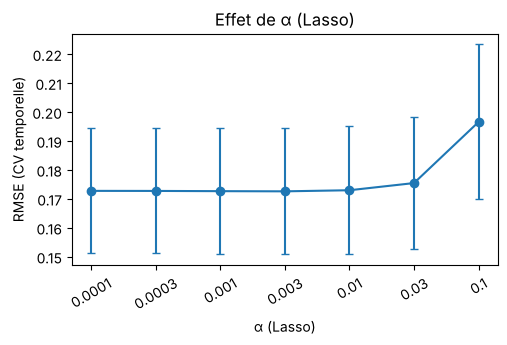

In [ ]:
# Variation d'un hyperparamètre : α du Lasso — validation croisée temporelle sur l'ENTRAÎNEMENT
alphas = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1]
lignes = []
for al in alphas:
    mdl = make_pipeline(StandardScaler(), Lasso(alpha=al, max_iter=20000)); m, s = cv_rmse(mdl)
    nb = (mdl.fit(X_ent, y_ent)[-1].coef_ != 0).sum(); lignes.append((al, m, s, nb))
t_l = pd.DataFrame(lignes, columns=['valeur', 'RMSE CV', 'écart-type', 'nb variables']); display(t_l.round(5)); tracer_variation(t_l, 'α (Lasso)')

# Choix automatique de α par validation croisée temporelle (LassoCV) puis évaluation unique sur le test
lcv = make_pipeline(StandardScaler(), LassoCV(alphas=np.logspace(-4.5, -1, 40), cv=TimeSeriesSplit(5), max_iter=20000)).fit(X_ent, y_ent)
print('α choisi par LassoCV :', round(lcv[-1].alpha_, 5), '| variables non nulles :', int((lcv[-1].coef_ != 0).sum()), '→', [v for v, k in zip(VARIABLES, lcv[-1].coef_) if k != 0])
display(pd.DataFrame([evaluer('Lasso (α par CV temporelle)', lcv)]).set_index('modèle').round(4))


**Lecture.** Le nombre de variables retenues chute avec α : 17 (α = 10⁻⁴), 15 (10⁻³), 11 (3·10⁻³), 5 (10⁻²), 1 (3·10⁻²), 0 (10⁻¹). Le meilleur RMSE de validation croisée est obtenu à **α = 0,003 (11 variables, 0,17256)** ; α = 0,01 ne garde que **5 variables pour 0,17294** (quasi identique) : un modèle bien plus simple pour presque la même performance. À α = 0,03 il ne reste que `ecart_moy3` (0,1754) ; à α = 0,1 le modèle est constant (0,1966, pire que tout). `LassoCV` à validation temporelle choisit α = 0,0024 (12 variables) et donne sur le test RMSE **0,1682**, MAE 0,0908, R² 0,160.

#### Tableau comparatif final (les 3 modèles + références)

                               RMSE     MAE      R²
modèle                                             
Référence : inflation nulle  0.1836  0.0766 -0.0001
Référence : persistance      0.3957  0.1759 -3.6445
Régression linéaire          0.1688  0.0940  0.1546
Ridge (α=100, CV)            0.1688  0.0939  0.1551
Lasso (α par CV)             0.1682  0.0908  0.1602
         observée   Lasso   Ridge  Linéaire
mois                                       
2011-05    0.0058  0.0076 -0.0003   -0.0003
2011-06   -0.0086  0.0014  0.0102    0.0102
2011-07   -0.0218  0.0046  0.0038    0.0037
2011-08    0.0082  0.0116  0.0156    0.0156
2011-09   -0.0034  0.0040  0.0050    0.0050
2011-10   -0.0110 -0.0018 -0.0099   -0.0100
2011-11    0.0163  0.0175  0.0261    0.0262

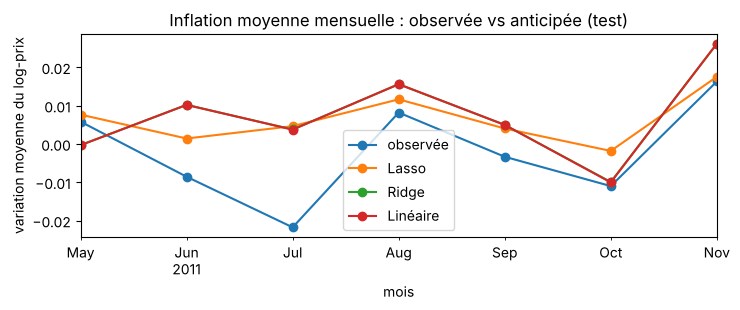

In [ ]:
# Synthèse des trois modèles sur le même découpage temporel (entraînement : jusqu'à mars 2011 ; test : avril → octobre 2011)
synthese = pd.DataFrame([base_zero, base_pers, evaluer('Régression linéaire', modele_lin), evaluer(f'Ridge (α={alpha_star:g}, CV)', modele_ridge_cv), evaluer('Lasso (α par CV)', lcv)]).set_index('modèle')
display(synthese.round(4))
fig, ax = plt.subplots(figsize=(7.5, 3.2)); agr = inflation_agregee(lcv.predict(X_test)).rename(columns={'anticipée': 'Lasso'})
agr['Ridge'] = inflation_agregee(modele_ridge_cv.predict(X_test))['anticipée']; agr['Linéaire'] = inflation_agregee(pred_lin)['anticipée']
agr.plot(ax=ax, marker='o'); ax.set_title('Inflation moyenne mensuelle : observée vs anticipée (test)'); ax.set_ylabel('variation moyenne du log-prix'); plt.tight_layout(); plt.show()
print(agr.round(4))


### Synthèse des trois algorithmes sur le thème « anticipations d'inflation »
Sur le test, les trois modèles se valent : RMSE entre **0,1682 et 0,1688** (contre 0,1836 pour « inflation nulle » et 0,396 pour la « persistance »), R² ≈ **0,155 à 0,160**. Lasso est très légèrement meilleur sur les trois métriques (RMSE, MAE, R²), mais l'écart est bien plus petit que la variabilité entre plis de validation croisée (≈ 0,02) : on ne peut pas dire qu'il est *significativement* meilleur. Ridge est quasi identique aux MCO (n ≫ p). **Ce qu'il faut retenir** : (i) l'information utile est surtout le **retour à la moyenne** du prix et la **saisonnalité** ; (ii) les modèles linéaires plafonnent vers R² ≈ 0,16 car les prix sont rigides (≈ 78 % inchangés) et les effets non linéaires — piste naturelle pour la régression polynomiale, les arbres et les forêts (sections 4 à 7) ; (iii) ces résultats portent sur un proxy construit à partir d'un seul commerçant et ne sont pas des prévisions d'inflation officielle.

## 4. Régression polynomiale

**Question ciblée (Partie B) :** Quelle difficulté pose la croissance du nombre de caractéristiques polynomiales ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
modele=make_pipeline(StandardScaler(),PolynomialFeatures(degree=2,include_bias=False),Ridge(alpha=60.)).fit(Xr_ent,yr_ent)
print('MAE:',mean_absolute_error(yr_test,modele.predict(Xr_test)))

MAE: 41.24579873763898


## 5. Arbre de régression

**Question ciblée (Partie B) :** Pourquoi limiter la profondeur et le nombre minimal d’observations par feuille ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.tree import DecisionTreeRegressor
modele=DecisionTreeRegressor(max_depth=3,min_samples_leaf=8,random_state=GRAINE).fit(Xr_ent,yr_ent)
print('R²:',r2_score(yr_test,modele.predict(Xr_test)))

R²: 0.4314003646672102


## 6. Forêt aléatoire — régression

**Question ciblée (Partie B) :** Décrivez le bootstrap et expliquez le rôle de la moyenne des arbres.

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.ensemble import RandomForestRegressor
modele=RandomForestRegressor(n_estimators=120,min_samples_leaf=4,random_state=GRAINE,n_jobs=-1).fit(Xr_ent,yr_ent)
print('MAE:',mean_absolute_error(yr_test,modele.predict(Xr_test)))

MAE: 42.58294190565993


## 7. Gradient Boosting — régression

**Question ciblée (Partie B) :** Pourquoi les arbres sont-ils entraînés séquentiellement dans le boosting ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.ensemble import HistGradientBoostingRegressor
modele=HistGradientBoostingRegressor(max_iter=110,max_leaf_nodes=12,random_state=GRAINE).fit(Xr_ent,yr_ent)
print('RMSE:',mean_squared_error(yr_test,modele.predict(Xr_test))**.5)

RMSE: 57.12732848789662


## 8. Régression logistique

**Question ciblée (Partie B) :** Comment interpréter une probabilité prédite et ajuster le seuil de classification ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.linear_model import LogisticRegression
modele=make_pipeline(StandardScaler(),LogisticRegression(C=.2,max_iter=1500,random_state=GRAINE)).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9888888888888889


## 9. KNN

**Question ciblée (Partie B) :** Quel est l’effet d’une distance normalisée et du nombre de voisins ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
modele=make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=9,weights='distance')).fit(Xc_ent,yc_ent)
print('Exactitude:',accuracy_score(yc_test,modele.predict(Xc_test)))

Exactitude: 0.965034965034965


## 10. Naive Bayes

**Question ciblée (Partie B) :** Quelle hypothèse d’indépendance conditionnelle est faite par Naive Bayes ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.naive_bayes import GaussianNB
modele=GaussianNB(var_smoothing=1e-8).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9621621621621622


## 11. Arbre de décision

**Question ciblée (Partie B) :** Comment calculer l’impureté de Gini et choisir une séparation ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
modele=DecisionTreeClassifier(max_depth=3,min_samples_leaf=5,random_state=GRAINE).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9560439560439561


## 12. Forêt aléatoire — classification

**Question ciblée (Partie B) :** Pourquoi une forêt est-elle généralement moins instable qu’un arbre seul ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
modele=RandomForestClassifier(n_estimators=110,max_depth=6,random_state=GRAINE,n_jobs=-1).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9613259668508287


## 13. SVM

**Question ciblée (Partie B) :** À quoi servent les vecteurs de support et le paramètre C ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.svm import SVC
modele=make_pipeline(StandardScaler(),SVC(kernel='rbf',C=2.,gamma='scale')).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9888888888888889


## 14. Gradient Boosting — classification

**Question ciblée (Partie B) :** Comment corriger progressivement les erreurs de classification ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
modele=HistGradientBoostingClassifier(max_iter=100,max_leaf_nodes=10,random_state=GRAINE).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9726775956284153


## 15. AdaBoost

**Question ciblée (Partie B) :** Comment AdaBoost repondère-t-il les exemples difficiles ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.ensemble import AdaBoostClassifier
modele=AdaBoostClassifier(n_estimators=90,learning_rate=.7,random_state=GRAINE).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9726775956284153


## 16. XGBoost

**Question ciblée (Partie B) :** Quel est le rôle de la régularisation et du learning_rate dans XGBoost ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from xgboost import XGBClassifier
modele=XGBClassifier(n_estimators=100,max_depth=2,learning_rate=.09,random_state=GRAINE,eval_metric='logloss').fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.978021978021978


## 17. K-means

**Question ciblée (Partie B) :** Comment affecter chaque vin à son centroïde puis recalculer celui-ci ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

Silhouette: 0.5610505693103246


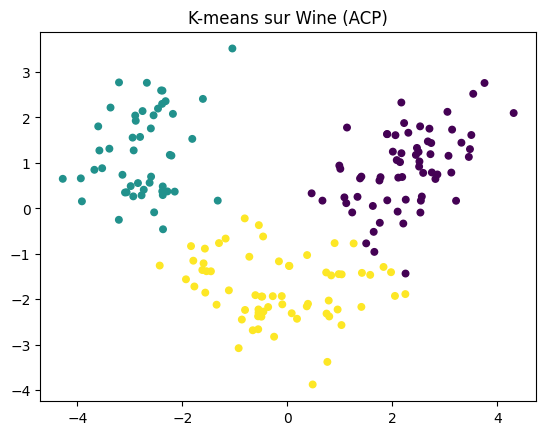

In [ ]:
from sklearn.cluster import KMeans
modele=KMeans(n_clusters=3,n_init=15,random_state=GRAINE).fit(X_clu)
print('Silhouette:',silhouette_score(X_clu,modele.labels_))
plt.scatter(X_clu[:,0],X_clu[:,1],c=modele.labels_,s=22);plt.title('K-means sur Wine (ACP)');plt.show()

## 18. Classification hiérarchique

**Question ciblée (Partie B) :** Que montre un dendrogramme et comment définit-on le lien de Ward ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.cluster import AgglomerativeClustering
etiquettes=AgglomerativeClustering(n_clusters=3,linkage='ward').fit_predict(X_clu)
print('Silhouette:',silhouette_score(X_clu,etiquettes))

Silhouette: 0.5590883962040383


## 19. DBSCAN

**Question ciblée (Partie B) :** À quoi correspondent les points marqués comme bruit par DBSCAN ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.cluster import DBSCAN
etiquettes=DBSCAN(eps=.7,min_samples=6).fit_predict(X_clu)
print('Groupes:',len(set(etiquettes)-{-1}),'Bruit:',int((etiquettes==-1).sum()))

Groupes: 2 Bruit: 8


## 20. Mélanges gaussiens

**Question ciblée (Partie B) :** En quoi les appartenances probabilistes diffèrent-elles d’une affectation dure ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.mixture import GaussianMixture
modele=GaussianMixture(n_components=3,covariance_type='full',random_state=GRAINE).fit(X_clu)
etiquettes=modele.predict(X_clu)
print('Poids des groupes:',modele.weights_.round(3),'Silhouette:',silhouette_score(X_clu,etiquettes))

Poids des groupes: [0.38  0.269 0.351] Silhouette: 0.5591116207103001


## 21. ACP

**Question ciblée (Partie B) :** Que mesure la variance expliquée par les deux axes de l’ACP ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

Variance expliquée: [0.12  0.096]


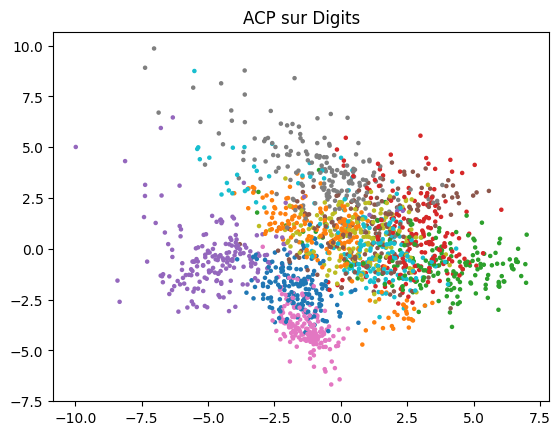

In [ ]:
from sklearn.decomposition import PCA
modele=PCA(n_components=2,random_state=GRAINE).fit(X_images)
projection=modele.transform(X_images)
print('Variance expliquée:',modele.explained_variance_ratio_.round(3))
plt.scatter(projection[:,0],projection[:,1],c=jeu_images.target,cmap='tab10',s=5);plt.title('ACP sur Digits');plt.show()

## 22. t-SNE

**Question ciblée (Partie B) :** Pourquoi la distance entre groupes éloignés peut-elle être trompeuse en t-SNE ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

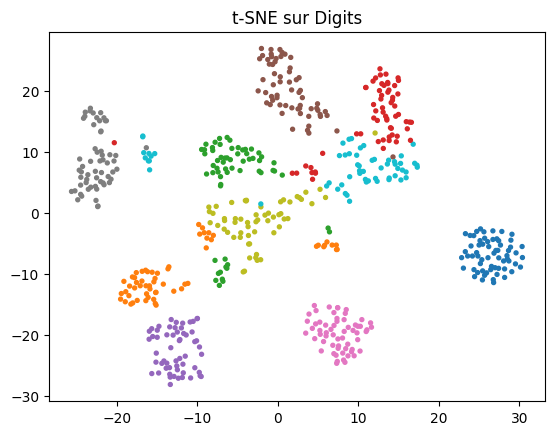

In [ ]:
from sklearn.manifold import TSNE
projection=TSNE(n_components=2,perplexity=35,random_state=GRAINE,init='pca').fit_transform(X_images[:600])
plt.scatter(projection[:,0],projection[:,1],c=jeu_images.target[:600],cmap='tab10',s=8);plt.title('t-SNE sur Digits');plt.show()

## 23. UMAP

**Question ciblée (Partie B) :** Quel est l’effet de n_neighbors et min_dist sur les voisinages ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


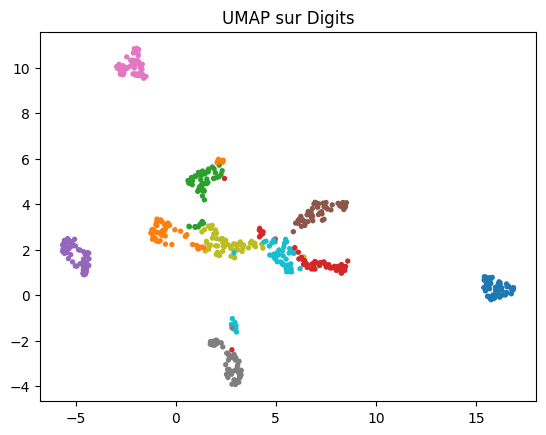

In [ ]:
import umap
projection=umap.UMAP(n_components=2,n_neighbors=20,min_dist=.15,random_state=GRAINE).fit_transform(X_images[:600])
plt.scatter(projection[:,0],projection[:,1],c=jeu_images.target[:600],cmap='tab10',s=8);plt.title('UMAP sur Digits');plt.show()

## 24. Isolation Forest

**Question ciblée (Partie B) :** Pourquoi une observation statistiquement atypique n’est-elle pas forcément une erreur ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.ensemble import IsolationForest
# Recherche d'observations atypiques dans les caractéristiques de vins (sans ajouter de faux points)
modele=IsolationForest(contamination=.05,n_estimators=150,random_state=GRAINE).fit(X_clu)
indices=np.where(modele.predict(X_clu)==-1)[0]
print('Nombre de vins atypiques:',len(indices),'Indices (extrait):',indices[:12])

Nombre de vins atypiques: 9 Indices (extrait): [  3  14  18  59  80 115 146 158 177]


## 25. Bandits manchots

**Question ciblée (Partie B) :** Comment calculer une estimation du gain moyen de chaque bras ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
# Bandit simulé à 4 choix : la politique choisit successivement chaque bras
generateur=np.random.default_rng(GRAINE)
probabilites=np.array([.15,.4,.6,.75]);sommes=np.zeros(4);comptes=np.zeros(4,dtype=int)
for t in range(800):
    bras=t%4
    gain=int(generateur.random()<probabilites[bras]);sommes[bras]+=gain;comptes[bras]+=1
print('Probabilités estimées:',(sommes/comptes).round(3))

Probabilités estimées: [0.205 0.335 0.605 0.765]


## 26. Epsilon-greedy

**Question ciblée (Partie B) :** Quelle différence entre exploration aléatoire et exploitation du meilleur bras estimé ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
# Epsilon-greedy sur les mêmes 4 bras simulés
generateur=np.random.default_rng(GRAINE)
probabilites=np.array([.15,.4,.6,.75]);sommes=np.zeros(4);comptes=np.zeros(4,dtype=int);epsilon=.15
for t in range(1200):
    bras=int(generateur.integers(4)) if generateur.random()<epsilon else int(np.argmax((sommes+1)/(comptes+2)))
    gain=int(generateur.random()<probabilites[bras]);sommes[bras]+=gain;comptes[bras]+=1
print('Nombre de choix:',comptes,'Estimations:',(sommes/np.maximum(comptes,1)).round(3))

Nombre de choix: [  55   53   44 1048] Estimations: [0.182 0.377 0.614 0.751]


## 27. Q-learning

**Question ciblée (Partie B) :** Comment calculer une cible de Bellman dans Taxi et pourquoi le max intervient-il ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
# Q-learning manuel sur Taxi-v4 (corrigé) : exploration epsilon-greedy
# Travail de : IBRAHIM EL-MERZOUKI (25007743)
import gymnasium as gym
import numpy as np

env=gym.make('Taxi-v4')
Q=np.zeros((env.observation_space.n,env.action_space.n))
generateur=np.random.default_rng(GRAINE)

for episode in range(3000):
    etat,_=env.reset(seed=GRAINE+episode)
    epsilon=max(.07,1-episode/2400)
    for pas in range(200):
        action=int(generateur.integers(env.action_space.n)) if generateur.random()<epsilon else int(np.argmax(Q[etat]))
        suivant,recompense,termine,tronque,_=env.step(action)
        cible=recompense+(0 if termine else .96*np.max(Q[suivant]))
        Q[etat,action]+=.2*(cible-Q[etat,action])
        etat=suivant
        if termine or tronque:break

print('Q-learning Taxi — taille de Q:',Q.shape,'Valeurs du premier état:',Q[0].round(2))
env.close()

Q-learning Taxi — taille de Q: (500, 6) Valeurs du premier état: [0. 0. 0. 0. 0. 0.]


## 28. SARSA

**Question ciblée (Partie B) :** Pourquoi SARSA met-il à jour Q avec l’action suivante réellement choisie ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
# Q-learning manuel sur Taxi : exploration epsilon-greedy
import gymnasium as gym
TAXI_ID = 'Taxi-v4' if 'Taxi-v4' in gym.registry else 'Taxi-v3'   # Taxi-v3 supprimé dans les versions récentes
env=gym.make(TAXI_ID);Q=np.zeros((env.observation_space.n,env.action_space.n));generateur=np.random.default_rng(GRAINE)
for episode in range(3000):
    etat,_=env.reset(seed=GRAINE+episode);epsilon=max(.07,1-episode/2400)
    for pas in range(200):
        action=int(generateur.integers(env.action_space.n)) if generateur.random()<epsilon else int(np.argmax(Q[etat]))
        suivant,recompense,termine,tronque,_=env.step(action)
        cible=recompense+(0 if termine else .96*np.max(Q[suivant]))
        Q[etat,action]+=.2*(cible-Q[etat,action]);etat=suivant
        if termine or tronque:break
print('Environnement :',TAXI_ID)
print('Q-learning Taxi — taille de Q:',Q.shape,'Valeurs du premier état:',Q[0].round(2))
env.close()

Environnement : Taxi-v4
Q-learning Taxi — taille de Q: (500, 6) Valeurs du premier état: [0. 0. 0. 0. 0. 0.]


## 29. DQN — cible conceptuelle

**Question ciblée (Partie B) :** Pourquoi un DQN complet a-t-il besoin d’un réseau cible et d’une mémoire de rejouement ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
# DQN : calcul pédagogique d'une cible de Bellman (aucun réseau entraîné)
recompenses=np.array([2.,-1.,10.,0.]);termine=np.array([False,False,True,False])
q_cible_etat_suivant=np.array([5.,3.,7.,2.]);gamma=.9
cibles=recompenses+gamma*(~termine)*q_cible_etat_suivant
print('Cibles DQN conceptuelles:',cibles)
# Un DQN complet utiliserait un réseau en ligne, un réseau cible et un replay buffer.

Cibles DQN conceptuelles: [ 6.5  1.7 10.   1.8]


## Annexes — Implémentations manuelles (Partie B)

Reproduire les principes de la descente de gradient et de K-means sans utiliser leurs estimateurs prédéfinis. Comparer les résultats aux références scikit-learn.

In [ ]:
# Descente de gradient manuelle pour une régression linéaire sur Diabetes, avec 1 variable
x = X_reg[:, 2].copy()
x = (x - x.mean()) / x.std()
y = y_reg.copy()

poids_man = 0.
biais_man = y.mean()
pas_man = 0.015

for iteration in range(3000):
    erreur = poids_man * x + biais_man - y
    poids_man -= pas_man * 2 * np.mean(erreur * x)
    biais_man -= pas_man * 2 * np.mean(erreur)

print('Manuel:', round(poids_man, 3), round(biais_man, 3))
from sklearn.linear_model import LinearRegression
modele_ref = LinearRegression().fit(x.reshape(-1, 1), y)
print('Scikit-learn:', modele_ref.coef_.round(3), round(modele_ref.intercept_, 3))

Manuel: 45.16 152.133
Scikit-learn: [45.16] 152.133


In [ ]:
# K-means manuel sur la projection Wine, avec centroïdes et inertie
valeurs = X_clu.copy()
k = 3
generateur = np.random.default_rng(GRAINE)
centroides = valeurs[generateur.choice(len(valeurs), size=k, replace=False)].copy()

for iteration in range(100):
    distances = ((valeurs[:, None, :] - centroides[None, :, :]) ** 2).sum(axis=2)
    groupes = distances.argmin(axis=1)
    nouveaux = np.array([valeurs[groupes == j].mean(axis=0) if np.any(groupes == j) else centroides[j] for j in range(k)])
    if np.allclose(nouveaux, centroides):
        break
    centroides = nouveaux

inertie = np.sum((valeurs - centroides[groupes]) ** 2)
from sklearn.cluster import KMeans
reference = KMeans(n_clusters=k, n_init=15, random_state=GRAINE).fit(valeurs)
print('Inertie manuelle:', round(inertie, 2), 'Inertie sklearn:', round(reference.inertia_, 2))

Inertie manuelle: 260.02 Inertie sklearn: 259.51


Le **Q-learning tabulaire manuel** est présenté à la section 27 sur Taxi-v3, et **SARSA** à la section 28. Scikit-learn ne propose pas de Q-learning tabulaire équivalent. Comparer plutôt les deux méthodes avec les mêmes paramètres, graines, nombre d’épisodes et métriques de succès.